In [79]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

In [80]:
iris = load_iris()

X = iris.data
y = iris.target

print("X shape:", X.shape)
print("y shape:", y.shape)

print("Classes:", iris.target_names)

X shape: (150, 4)
y shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [81]:
df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["target"] = y

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [82]:
print(df.shape)
print(df.info())
print(df["target"].value_counts())

(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None
target
0    50
1    50
2    50
Name: count, dtype: int64


In [83]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (120, 4)
X_test: (30, 4)


In [84]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [85]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(4,)),

    tf.keras.layers.Dense(16, activation="relu"),

    tf.keras.layers.Dense(8, activation="relu"),

    tf.keras.layers.Dense(3, activation="softmax")
])

In [86]:
model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [87]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [88]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    verbose=1
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step - accuracy: 0.2917 - loss: 1.1020 - val_accuracy: 0.3333 - val_loss: 1.1064
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3438 - loss: 1.0722 - val_accuracy: 0.3333 - val_loss: 1.0812
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3438 - loss: 1.0449 - val_accuracy: 0.4167 - val_loss: 1.0577
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3854 - loss: 1.0199 - val_accuracy: 0.4167 - val_loss: 1.0357
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4479 - loss: 0.9958 - val_accuracy: 0.4583 - val_loss: 1.0173
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4479 - loss: 0.9758 - val_accuracy: 0.4583 - val_loss: 1.0014
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5417 - loss: 0.9568 - val_accuracy: 0.5000 - val_loss: 0.9866
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6250 - loss: 0.9402 - val_accuracy: 0.5417 - val_loss: 0.9733

In [89]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.8000 - loss: 0.3962
Test Loss: 0.39616158604621887
Test Accuracy: 0.800000011920929


In [90]:
y_probability = model.predict(X_test)

print(y_probability[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
[[0.9516852  0.02557335 0.02274149]
 [0.0063642  0.3519761  0.64165974]
 [0.08859744 0.695458   0.21594453]
 [0.05295829 0.738396   0.20864572]
 [0.96201783 0.01843479 0.01954739]]


In [91]:
y_pred = np.argmax(y_probability, axis=1)

print(y_pred[:10])

[0 2 1 1 0 2 0 0 2 1]


In [92]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.40      0.57        10
   virginica       0.62      1.00      0.77        10

    accuracy                           0.80        30
   macro avg       0.88      0.80      0.78        30
weighted avg       0.88      0.80      0.78        30



In [93]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[10  0  0]
 [ 0  4  6]
 [ 0  0 10]]


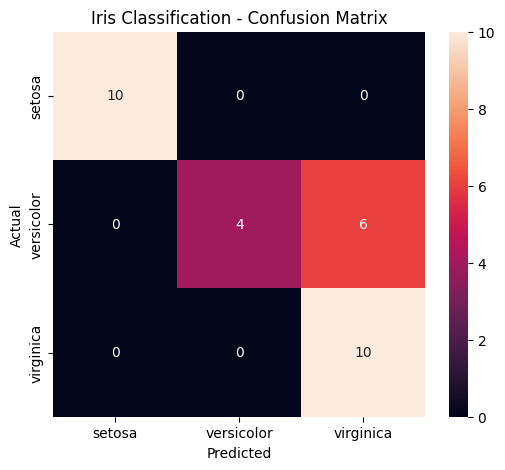

In [94]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Iris Classification - Confusion Matrix")

plt.show()

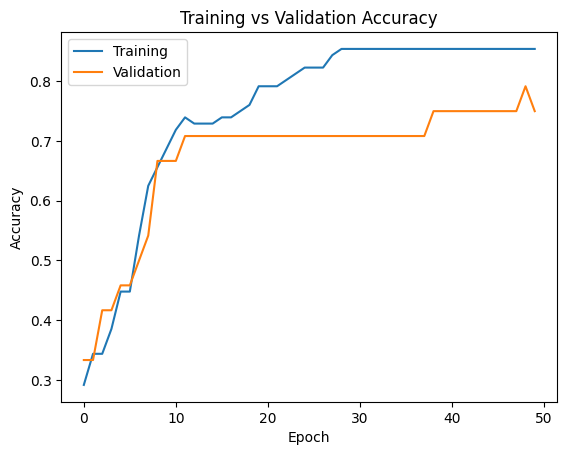

In [95]:
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Training", "Validation"])

plt.title("Training vs Validation Accuracy")

plt.show()

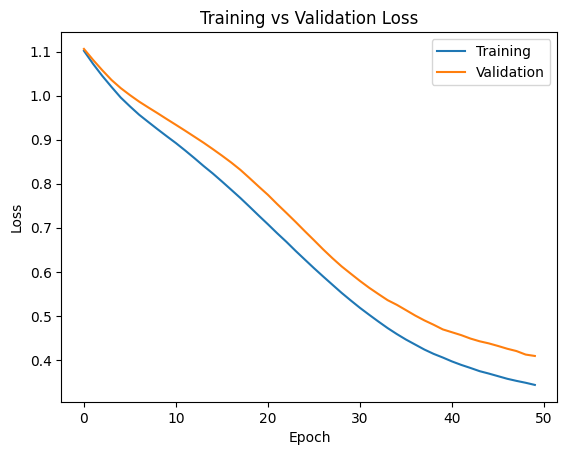

In [96]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend(["Training", "Validation"])

plt.title("Training vs Validation Loss")

plt.show()

In [97]:
new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

In [98]:
new_flower_scaled = scaler.transform(new_flower)

In [99]:
prediction = model.predict(new_flower_scaled)

predicted_class = np.argmax(prediction, axis=1)[0]

print("Predicted Class:", predicted_class)
print("Flower:", iris.target_names[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
Predicted Class: 0
Flower: setosa


In [100]:
model.save("iris_tensorflow_model.keras")

In [101]:
loaded_model = tf.keras.models.load_model(
    "iris_tensorflow_model.keras"
)

In [102]:
prediction = loaded_model.predict(new_flower_scaled)

predicted_class = np.argmax(prediction, axis=1)[0]

print(iris.target_names[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
setosa
